In [ ]:
import numpy as np
from scipy.stats import gaussian_kde

import jax
import jax.numpy as jnp
import jax.scipy as jsp
import jax.random as jr
jax.config.update("jax_enable_x64", True)
import equinox as eqx
import optax
import matplotlib.pyplot as plt
from tqdm import trange

from flowjax.distributions import StandardNormal, Transformed
from flowjax.bijections import Coupling, RationalQuadraticSpline, Chain, Permute, Affine

# ==========================================
# 1. Define the 3D GMM Dataset
# ==========================================
class Params:
    def __init__(self):
        self.asymptotic = 200.0
        self.inflexion = 500.0
        self.tau = 150.0
        self.cov_latent = jnp.diag(jnp.array([40.0, 100.0, 100.0]))

def sample_gmm_data(key, n):
    p = Params()
    key1, key_mean, key_comp, key_norm = jax.random.split(key, 4)
    
    base_mean = jnp.array([p.asymptotic, p.inflexion, p.tau])
    L = jnp.linalg.cholesky(p.cov_latent)
    spread = 100.0 
    
    gmm_means = base_mean + jax.random.normal(key_mean, shape=(3, 3)) * spread
    components = jax.random.randint(key_comp, shape=(n, 3), minval=0, maxval=3)
    assigned_means = gmm_means[components, jnp.arange(3)] 
    
    z = jax.random.normal(key_norm, shape=(n, 3)) @ L.T + assigned_means
    return z

key = jr.PRNGKey(42)
key, subkey = jr.split(key)
num_samples = 10000
x_train = sample_gmm_data(subkey, num_samples)

print(f"Generated {num_samples} 3D samples.")
print(f"Data Means: {jnp.mean(x_train, axis=0)}")
print(f"Data Std: {jnp.std(x_train, axis=0)}\n")

# ==========================================
# 2. Define the Multi-Layer Architecture
# ==========================================
bound = 5.0
K = 8
num_layers = 12  # Number of coupling layers
base_dist = StandardNormal((3,))

# Step 2a: Renormalizer at the beginning
# We roughly center the data by its expected base_mean and scale down by spread so it fits in [-bound, bound]
loc = jnp.mean(x_train, axis=0)
scale = jnp.std(x_train, axis=0)
renormalizer = Affine(loc=loc, scale=scale)

# Step 2b: Build alternating Spline Couplings and Linear Layers[cite: 1]
layers = []


flow_key = jr.PRNGKey(127)
for i in range(num_layers):
    flow_key, subkey1, subkey2 = jr.split(flow_key, 3)
    
    # 1D Spline acting on 1 dim, conditioning on the other 2[cite: 1]
    coupling = Coupling(
        key=subkey1,
        transformer=RationalQuadraticSpline(knots=K, interval=bound),
        untransformed_dim=2,  # 2 dimensions passed through, 1 dimension transformed[cite: 1]
        dim=3,
        nn_width=32,
        nn_depth=2
    )
    layers.append(coupling)
    
    
    permutation = jax.random.permutation(subkey2, jnp.arange(3))
    linear_mixing = Permute(permutation)
    layers.append(linear_mixing)

layers.append(renormalizer)

# Compose the full bijection and flow[cite: 1]
bijection = Chain(layers)
flow = Transformed(base_dist, bijection)

# ==========================================
# 3. Define Adam Optimization[cite: 1]
# ==========================================
@eqx.filter_value_and_grad
def loss_fn(model, x):
    log_probs = jax.vmap(model.log_prob)(x)
    return -jnp.mean(log_probs)

@eqx.filter_jit
def train_step(model, state, x):
    loss, grads = loss_fn(model, x)
    updates, new_state = optim.update(grads, state)
    model = eqx.apply_updates(model, updates)
    return model, new_state, loss

learning_rate = 5e-2  
optim = optax.adam(learning_rate)
opt_state = optim.init(eqx.filter(flow, eqx.is_inexact_array))

# ==========================================
# 4. Mini-Batch Training Loop[cite: 1]
# ==========================================
epochs = 3000
batch_size = 1024
num_batches = num_samples // batch_size

print("Training starting using Adam...")
pbar = trange(epochs, desc="Training Flow")

for epoch in pbar:
    key, subkey = jr.split(key)
    indices = jr.permutation(subkey, num_samples)
    
    epoch_loss = 0.0
    for i in range(num_batches):
        batch_indices = indices[i * batch_size : (i + 1) * batch_size]
        x_batch = x_train[batch_indices]
        
        flow, opt_state, loss = train_step(flow, opt_state, x_batch)
        epoch_loss += loss
        
    avg_loss = epoch_loss / num_batches
    pbar.set_postfix(loss=f"{avg_loss:.4f}")

Generated 10000 3D samples.
Data Means: [273.31749332 607.15079226 150.41357565]
Data Std: [ 41.04529785 111.14218912 109.17680424]

Training starting using Adam...


Training Flow: 100%|██████████| 3000/3000 [23:23<00:00,  2.14it/s, loss=13.8686]


In [ ]:
import numpy as np
from scipy.stats import gaussian_kde

import jax
import jax.numpy as jnp
import jax.scipy as jsp
import jax.random as jr
jax.config.update("jax_enable_x64", True)
import equinox as eqx
import optax
import matplotlib.pyplot as plt
from tqdm import trange

from flowjax.distributions import StandardNormal, Transformed
from flowjax.bijections import Coupling, RationalQuadraticSpline, Chain, Affine, TriangularAffine, Permute

# ==========================================
# 1. Definição do Dataset GMM 3D
# ==========================================
class Params:
    def __init__(self):
        self.asymptotic = 200.0
        self.inflexion = 500.0
        self.tau = 150.0
        self.cov_latent = jnp.diag(jnp.array([40.0, 100.0, 100.0]))

def sample_gmm_data(key, n):
    p = Params()
    key1, key_mean, key_comp, key_norm = jax.random.split(key, 4)
    
    base_mean = jnp.array([p.asymptotic, p.inflexion, p.tau])
    L = jnp.linalg.cholesky(p.cov_latent)
    spread = 100.0 
    
    gmm_means = base_mean + jax.random.normal(key_mean, shape=(3, 3)) * spread
    components = jax.random.randint(key_comp, shape=(n, 3), minval=0, maxval=3)
    assigned_means = gmm_means[components, jnp.arange(3)] 
    
    z = jax.random.normal(key_norm, shape=(n, 3)) @ L.T + assigned_means
    return z

key = jr.PRNGKey(42)
key, subkey = jr.split(key)
num_samples = 10000
x_train = sample_gmm_data(subkey, num_samples)

print(f"Generated {num_samples} 3D samples.")
print(f"Data Means: {jnp.mean(x_train, axis=0)}")
print(f"Data Std: {jnp.std(x_train, axis=0)}\n")

# ==========================================
# 2. Construção da Arquitetura Multi-Layer
# ==========================================
bound = 5.0
K = 8
num_layers = 8  # Número de coupling layers
base_dist = StandardNormal((3,))

loc = jnp.mean(x_train, axis=0)
scale = jnp.std(x_train, axis=0)
renormalizer = Affine(loc=loc, scale=scale)

layers = []
flow_key = jr.PRNGKey(127)

for i in range(num_layers):
    flow_key, subkey1, subkey2 = jr.split(flow_key, 3)
    
    
    coupling = Coupling(
        key=subkey1,
        transformer=RationalQuadraticSpline(knots=K, interval=bound),
        untransformed_dim=2, 
        dim=3,
        nn_width=32,
        nn_depth=2
    )
    layers.append(coupling)
    
    triangular_mixing = TriangularAffine(jnp.zeros(3), jnp.eye(3))
    layers.append(triangular_mixing)
    
    permutation = jax.random.permutation(subkey2, jnp.arange(3))
    layers.append(Permute(permutation))

layers.append(renormalizer)

# Composição da bijeção e definição do fluxo de normalização[cite: 1]
bijection = Chain(layers)
flow = Transformed(base_dist, bijection)

# ==========================================
# 3. Definição da Otimização Adam[cite: 1]
# ==========================================
@eqx.filter_value_and_grad
def loss_fn(model, x):
    log_probs = jax.vmap(model.log_prob)(x)
    return -jnp.mean(log_probs)

@eqx.filter_jit
def train_step(model, state, x):
    loss, grads = loss_fn(model, x)
    updates, new_state = optim.update(grads, state)
    model = eqx.apply_updates(model, updates)
    return model, new_state, loss

learning_rate = 5e-3
optim = optax.adam(learning_rate)
opt_state = optim.init(eqx.filter(flow, eqx.is_inexact_array))

# ==========================================
# 4. Ciclo de Treino Mini-Batch[cite: 1]
# ==========================================
epochs = 3000
batch_size = 1024
num_batches = num_samples // batch_size

print("Training starting using Adam...")
pbar = trange(epochs, desc="Training Flow")

for epoch in pbar:
    key, subkey = jr.split(key)
    indices = jr.permutation(subkey, num_samples)
    
    epoch_loss = 0.0
    for i in range(num_batches):
        batch_indices = indices[i * batch_size : (i + 1) * batch_size]
        x_batch = x_train[batch_indices]
        
        flow, opt_state, loss = train_step(flow, opt_state, x_batch)
        epoch_loss += loss
        
    avg_loss = epoch_loss / num_batches
    pbar.set_postfix(loss=f"{avg_loss:.4f}")

Generated 10000 3D samples.
Data Means: [273.31749332 607.15079226 150.41357565]
Data Std: [ 41.04529785 111.14218912 109.17680424]

Training starting using Adam...


Training Flow: 100%|██████████| 3000/3000 [43:08<00:00,  1.16it/s, loss=13.7690] 


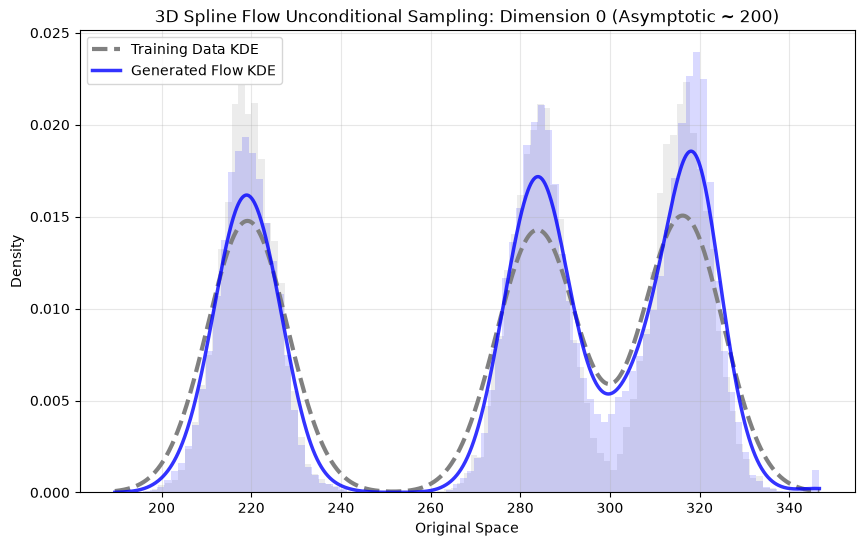

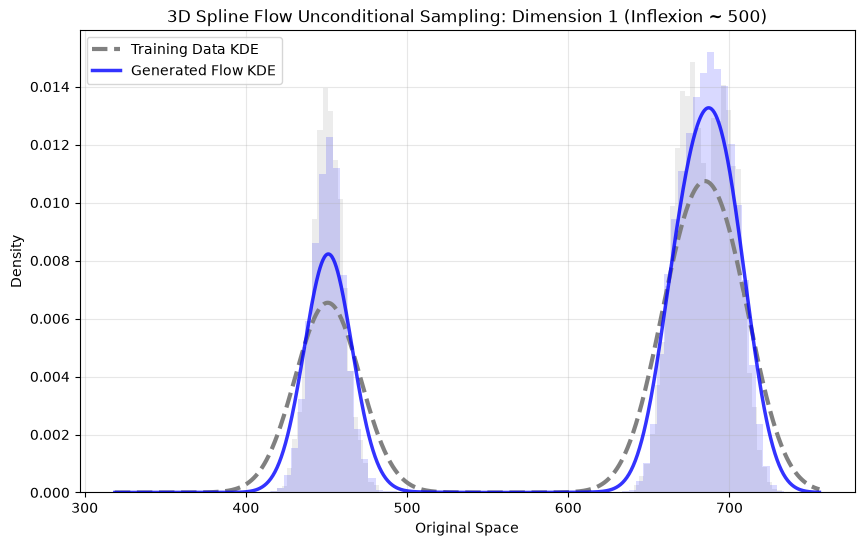

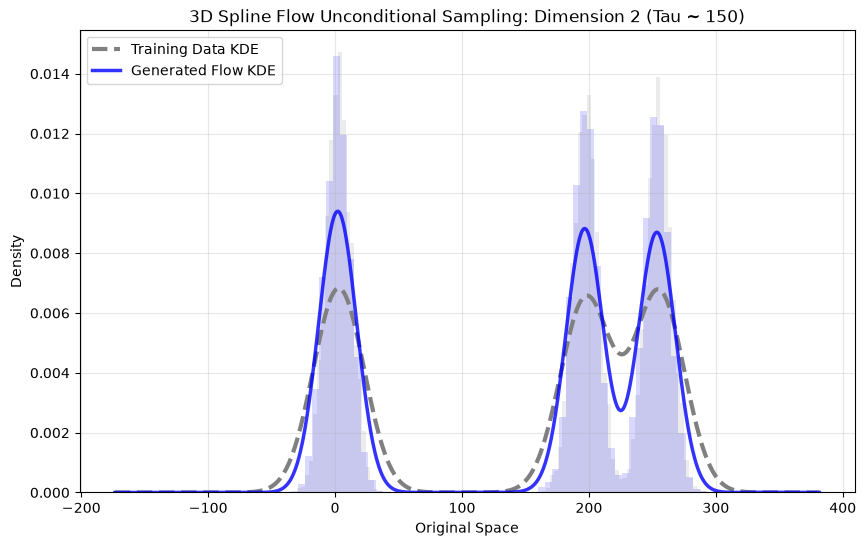

In [ ]:
# ==========================================
# 5. Unconditional Sampling and KDE Visualization
# ==========================================
# Draw 10,000 samples from the trained normalizing flow
sample_key = jax.random.key(999)
num_generated_samples = 100000
x_generated = flow.sample(sample_key, (num_generated_samples,))

dim_names = [
    "Dimension 0 (Asymptotic ~ 200)", 
    "Dimension 1 (Inflexion ~ 500)", 
    "Dimension 2 (Tau ~ 150)"
]

for d in range(3):
    plt.figure(figsize=(10, 6))
    
    # Convert to NumPy for SciPy KDE
    train_data_1d = np.array(x_train[:, d])
    gen_data_1d = np.array(x_generated[:, d])
    
    # Create an evaluation grid based on data bounds
    min_val = min(train_data_1d.min(), gen_data_1d.min())
    max_val = max(train_data_1d.max(), gen_data_1d.max())
    x_grid = np.linspace(min_val, max_val, 1000)
    
    # Fit KDEs
    kde_train = gaussian_kde(train_data_1d)
    kde_gen = gaussian_kde(gen_data_1d)
    
    # Plot KDE curves
    plt.plot(x_grid, kde_train(x_grid), color='gray', linewidth=3, linestyle='--', label="Training Data KDE")
    plt.plot(x_grid, kde_gen(x_grid), color='blue', linewidth=2.5, alpha=0.8, label="Generated Flow KDE")
    
    # Add light histograms in the background for visual context
    plt.hist(train_data_1d, bins=100, density=True, alpha=0.15, color='gray')
    plt.hist(gen_data_1d, bins=100, density=True, alpha=0.15, color='blue')
    
    plt.title(f"3D Spline Flow Unconditional Sampling: {dim_names[d]}")
    plt.xlabel("Original Space")
    plt.ylabel("Density")
    plt.legend()=13.4496]
    plt.grid(alpha=0.3)
    plt.show()